# Этап 3. RSS-фильтр на нижнем уровне: пилот β = 1 и β = 2

Код: `rssrl/shield.py` (фильтр), `rssrl/scenarios.py` (сцена и момент нарушения), `rssrl/logger.py` (временные ряды). Проверки: `tests/test_shield.py`.

**Пилот без PPO**: агент всегда выбирает IDLE — держит полосу и целевую скорость 25 м/с, на машину впереди сам не реагирует. Вся безопасность — только от фильтра.

**Сцена**: highway-v0, 50 фоновых машин (торможение ≤ 5 м/с²), 40 с. Когда прошло ≥ 3 с и агент идет за машиной впереди с зазором ≤ 1,1·d_min, эта машина становится нарушителем: тормозит с β·5 м/с² до остановки и стоит.

**Варианты агента** (все на одних и тех же 20 сценах):
- без фильтра;
- фильтр, реакция сразу (задержка 0);
- фильтр, задержка реакции ρ = 0,5 с (ровно предположение леммы 2).

In [1]:
import sys
sys.path.insert(0, '..')
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from rssrl.pilot import run_grid, plot_episode
from rssrl.rss import DEFAULT

FIG = Path('..') / 'results' / 'figures'
PILOT = Path('..') / 'results' / 'pilot_03'  # все графики столкновений, в git не идут
PILOT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False})
SEEDS = range(20)
VARIANTS = [(False, 0.0), (True, 0.0), (True, 0.5)]
NAMES = {(False, 0.0): 'без фильтра', (True, 0.0): 'фильтр, задержка 0',
         (True, 0.5): 'фильтр, задержка ρ'}

In [2]:
outcomes, logs = run_grid(SEEDS, [1.0, 2.0], VARIANTS)
outcomes['вариант'] = [NAMES[(s, d)] for s, d in zip(outcomes['shield'], outcomes['reaction_delay'])]
outcomes.to_csv(PILOT / 'outcomes.csv', index=False)
table = outcomes.pivot_table(index='вариант', columns='beta', values='collision', aggfunc='sum')
table.columns = [f'β = {b:g}' for b in table.columns]
table = table.loc[list(NAMES.values())]
print('Число эпизодов со столкновением из 20:')
table

Число эпизодов со столкновением из 20:


,β = 1,β = 2
вариант,,
без фильтра,20,20
"фильтр, задержка 0",0,7
"фильтр, задержка ρ",0,20


In [3]:
summary = outcomes.groupby(['вариант', 'beta']).agg(
    столкновений=('collision', 'sum'),
    из_них_с_нарушителем=('hit_violator', 'sum'),
    нарушение_было=('triggered', 'sum'),
    шагов_с_торможением_фильтра=('shield_steps', 'mean'),
    пробег_км=('distance_km', 'mean'),
).round(2)
summary

столкновений  из_них_с_нарушителем  нарушение_было  \
вариант            beta                                                       
без фильтра        1.0             20                    19              19   
                   2.0             20                    19              19   
фильтр, задержка 0 1.0              0                     0              20   
                   2.0              7                     7              20   
фильтр, задержка ρ 1.0              0                     0              20   
                   2.0             20                    20              20   

                         шагов_с_торможением_фильтра  пробег_км  
вариант            beta                                          
без фильтра        1.0                          0.00       0.31  
                   2.0                          0.00       0.30  
фильтр, задержка 0 1.0                        425.65       0.32  
                   2.0                        285.75       0.30  
фильтр, задержка ρ 1.0                        455.95       0.32  
                   2.0                         77.40       0.30

Что видно:
- **Без фильтра** агент врезается всегда, причем почти всегда в машину впереди, и при β = 1 тоже. Один раз агент врезался еще до начала нарушения.
- **С фильтром при β = 1** столкновений нет ни при одной задержке. Это и обещает RSS, когда допущение соблюдается. Пилот проверяет, что фильтр реализован правильно.
- **С фильтром при β = 2** столкновения появляются. Их доля сильно зависит от задержки реакции: при задержке ρ столкновения во всех сценах, при задержке 0 только в части.

## Одна сцена, два β (общие сцены)

До момента нарушения прогоны с β = 1 и β = 2 совпадают полностью: сцена одна и та же. Разница появляется только после того, как лидер начинает тормозить.

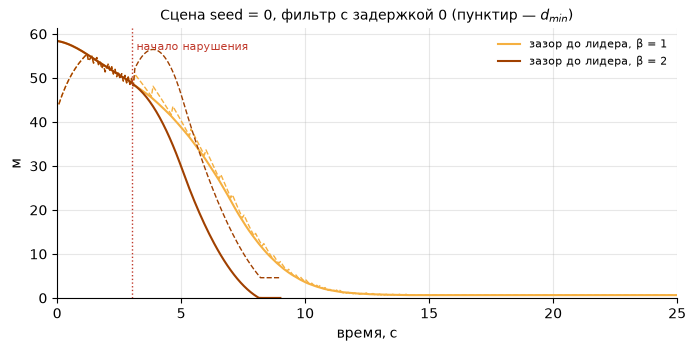

In [4]:
seed = int(outcomes[(outcomes.shield) & (outcomes.reaction_delay == 0) & (outcomes.beta == 2)
                    & outcomes.collision]['seed'].iloc[0])
fig, ax = plt.subplots(figsize=(8, 3.5))
for beta, color in [(1.0, '#f5b041'), (2.0, '#a04000')]:
    log = logs[(seed, beta, True, 0.0)]
    ax.plot(log['t'], log['vio_gap'].fillna(log['gap']).clip(lower=0), color=color,
            label=f'зазор до лидера, β = {beta:g}')
    ax.plot(log['t'], log['d_min'], color=color, linewidth=1, linestyle='--')
t0 = logs[(seed, 1.0, True, 0.0)]['vio_v'].first_valid_index() / 15
ax.axvline(t0, color='#c0392b', linewidth=1, linestyle=':')
ax.text(t0 + 0.2, ax.get_ylim()[1] * 0.92, 'начало нарушения', fontsize=8, color='#c0392b')
ax.set_xlim(0, min(25, logs[(seed, 1.0, True, 0.0)]['t'].max()))
ax.set_ylim(bottom=0)
ax.set_xlabel('время, с'); ax.set_ylabel('м')
ax.set_title(f'Сцена seed = {seed}, фильтр с задержкой 0 (пунктир — $d_{{min}}$)', fontsize=10)
ax.legend(frameon=False, fontsize=8); ax.grid(alpha=0.3)
fig.savefig(FIG / '03_same_scene_two_betas.png', dpi=150, bbox_inches='tight')
plt.show()

## Временные ряды каждого столкновения с фильтром

Для каждого столкновения: зазор и d_min, скорости, ускорения (команда политики, фактическое ускорение агента и нарушителя). Серым показаны шаги, где фильтр тормозит. Графики всех столкновений, включая варианты без фильтра, сохраняются в `results/pilot_03/`. Ниже показаны все столкновения при задержке 0 и первые 4 при задержке ρ.

In [5]:
crashes = outcomes[outcomes.collision].sort_values(['shield', 'reaction_delay', 'beta', 'seed'])
for _, o in crashes.iterrows():
    key = (o.seed, o.beta, o.shield, o.reaction_delay)
    fig, axes = plt.subplots(3, 1, figsize=(8, 7), sharex=True)
    plot_episode(logs[key], f"{o['вариант']}, β = {o.beta:g}, seed = {o.seed}", axes)
    name = f"{'shield' if o.shield else 'noshield'}_d{o.reaction_delay:g}_b{o.beta:g}_s{o.seed}.png"
    fig.savefig(PILOT / name, dpi=110, bbox_inches='tight')
    plt.close(fig)
print('сохранено графиков:', len(crashes))

сохранено графиков: 67


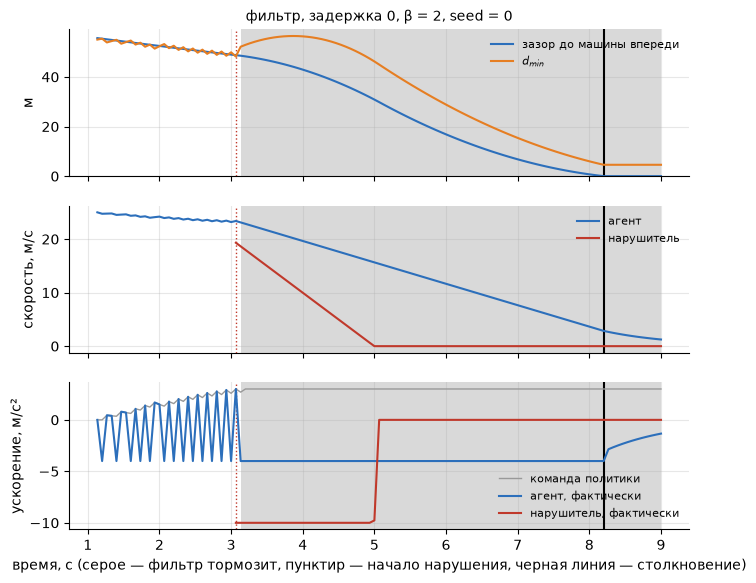

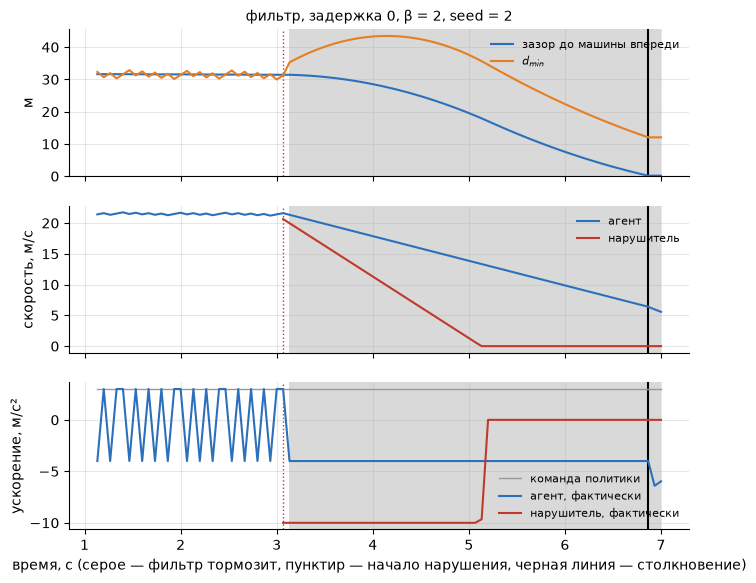

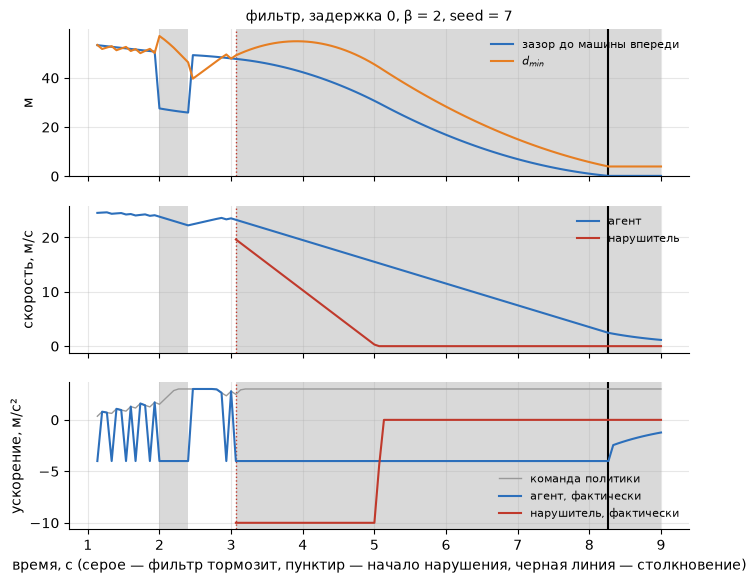

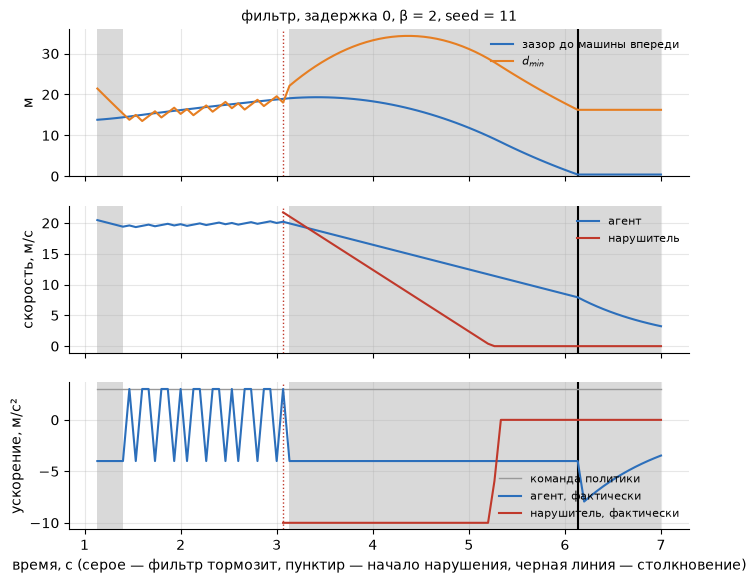

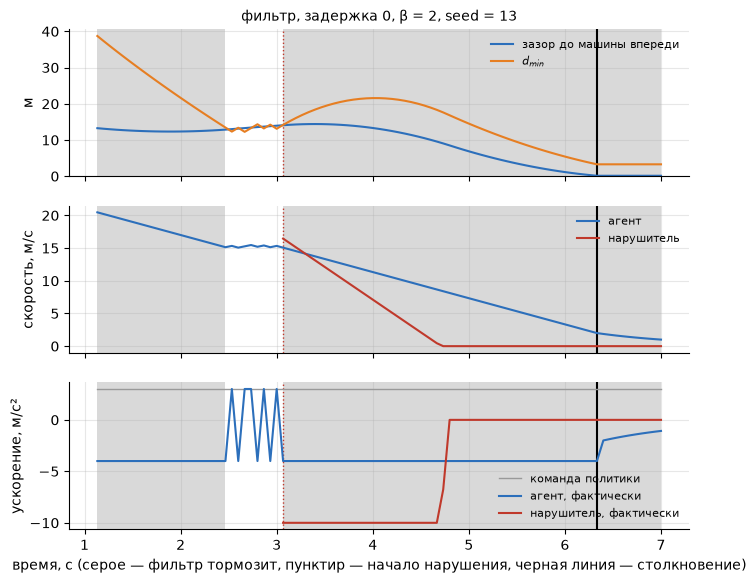

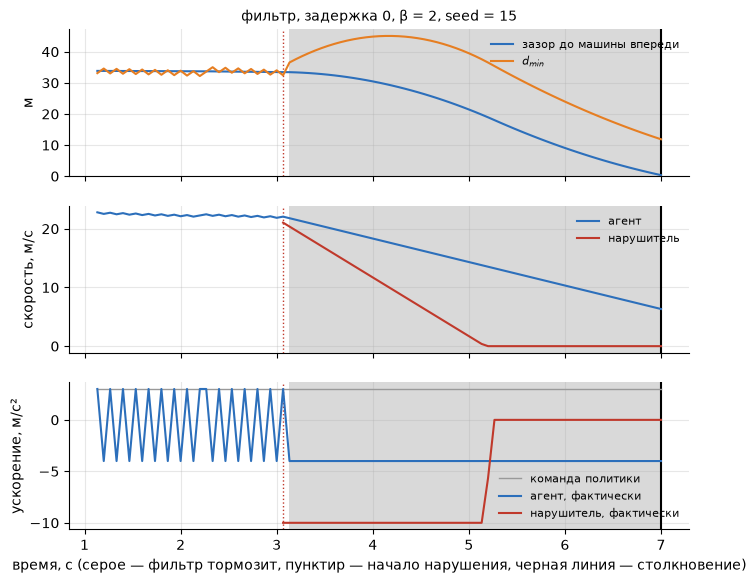

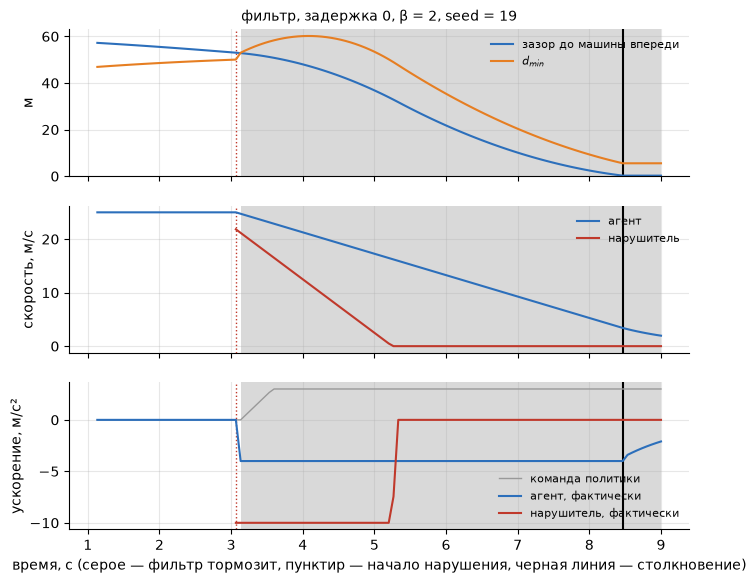

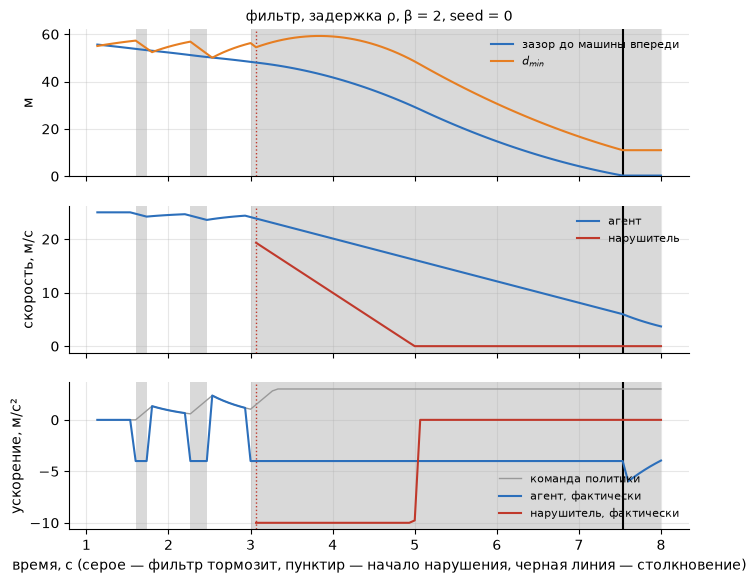

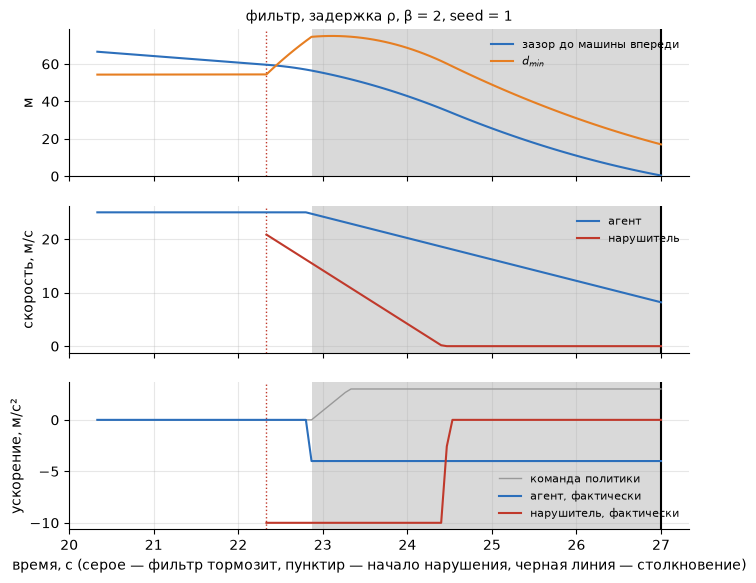

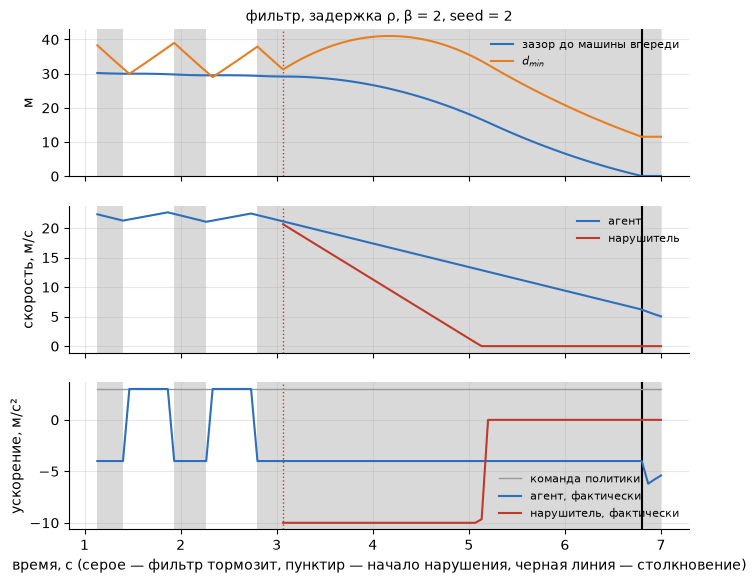

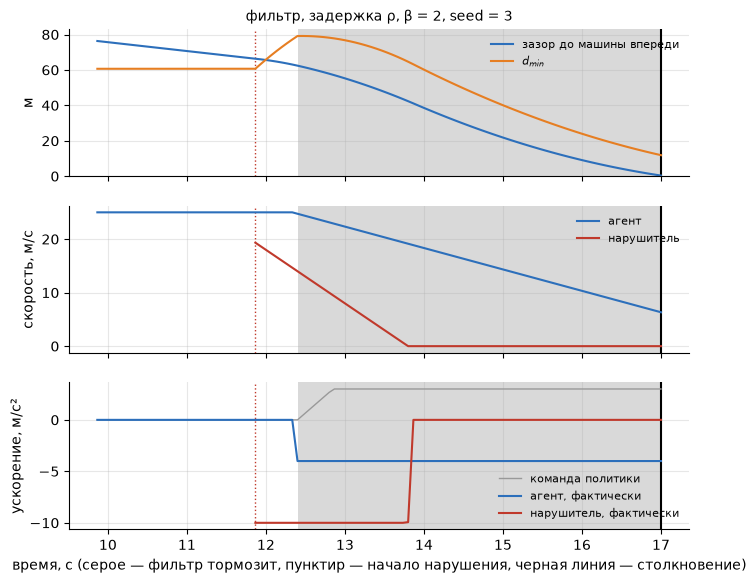

In [6]:
show = pd.concat([
    crashes[(crashes.shield) & (crashes.reaction_delay == 0)],
    crashes[(crashes.shield) & (crashes.reaction_delay == 0.5)].head(4),
])
for i, (_, o) in enumerate(show.iterrows()):
    key = (o.seed, o.beta, o.shield, o.reaction_delay)
    log = logs[key]
    t0 = log.loc[log['vio_v'].notna(), 't'].min()
    part = log[(log.t >= t0 - 2) & (log.t <= log.t.max())]
    fig, axes = plt.subplots(3, 1, figsize=(8, 6.5), sharex=True)
    plot_episode(part, f"{o['вариант']}, β = {o.beta:g}, seed = {o.seed}", axes)
    if i == 0:
        fig.savefig(FIG / '03_collision_example.png', dpi=150, bbox_inches='tight')
    plt.show()

## Сходится ли это с физикой?

При задержке 0 фильтр начинает тормозить с 4 м/с² практически сразу после начала нарушения (d_min мгновенно вырастает выше зазора). Тогда упрощенный прогноз: столкновение будет, если

$$\text{зазор}_0 < \frac{v_{агент}^2}{2\cdot 4} - \frac{v_{лидер}^2}{2\cdot 5\beta}.$$

Сравним прогноз с тем, что получилось в симуляции, для всех 40 эпизодов с фильтром и задержкой 0.

In [7]:
rows = []
for (seed, beta, shield, delay), log in logs.items():
    if not shield or delay != 0:
        continue
    i0 = log['vio_v'].first_valid_index()
    before = log.loc[i0 - 1]  # последний шаг до нарушения
    v_e, v_l, gap0 = before['ego_v'], before['vio_v'] if pd.notna(before['vio_v']) else log.loc[i0, 'v_front'], before['gap']
    need = v_e**2 / (2 * DEFAULT.a_min_brake) - v_l**2 / (2 * 5 * beta)
    o = outcomes[(outcomes.seed == seed) & (outcomes.beta == beta) & outcomes.shield & (outcomes.reaction_delay == 0)].iloc[0]
    rows.append({'seed': seed, 'β': beta, 'v агента': v_e, 'v лидера': v_l, 'зазор': gap0,
                 'нужно (прогноз)': need, 'прогноз: столкновение': gap0 < need,
                 'симуляция: столкновение': o.collision})
check = pd.DataFrame(rows).sort_values(['β', 'seed']).round(2)
agree = (check['прогноз: столкновение'] == check['симуляция: столкновение'])
print(f'прогноз совпал с симуляцией в {agree.sum()} из {len(check)} эпизодов')
check[check['β'] == 2.0]

прогноз совпал с симуляцией в 38 из 40 эпизодов


,seed,β,v агента,v лидера,зазор,нужно (прогноз),прогноз: столкновение,симуляция: столкновение
1,0,2.0,23.18,19.98,48.98,47.22,False,True
3,1,2.0,25.00,21.50,59.74,55.00,False,False
5,2,2.0,21.40,21.31,31.43,34.54,True,True
7,3,2.0,25.00,19.99,66.73,58.14,False,False
9,4,2.0,25.00,20.19,65.86,57.74,False,False
11,5,2.0,25.00,19.56,63.20,58.99,False,False
13,6,2.0,25.00,18.91,71.35,60.25,False,False
15,7,2.0,23.52,20.29,47.95,48.53,True,True
17,8,2.0,25.00,21.18,61.34,55.70,False,False
19,9,2.0,25.00,20.73,63.18,56.65,False,False


Прогноз и симуляция расходятся только в пограничных сценах, где запас по прогнозу меньше 2 м (seed 0 и 19). Прогноз этого не учитывает, но в момент нарушения агент в этих сценах еще разгонялся с +3 м/с², и фильтр начал тормозить на шаг позже (через 1/15 с). Это стоит порядка метра.

**Дребезг фильтра.** Перед нарушением, пока агент идет ровно на границе d_min, фильтр через шаг переключает ускорение: политика просит +3, фильтр отвечает −4 (пила на графике ускорения). На безопасность это не влияет, но плавной такую езду не назовешь. Это будет важно, когда на этапе 6 будем считать «лишние» срабатывания фильтра.

## Вывод пилота и решение, которое нужно принять

1. Фильтр реализован верно: при соблюдении допущения (β = 1) столкновений нет ни в одной сцене, а без фильтра они есть во всех.
2. При β = 2 столкновения есть, но их число **очень сильно зависит от задержки реакции фильтра**. При задержке 0 ρ остается только запасом в формуле: лемма разрешает агенту ρ секунд разгоняться, а фильтр тормозит сразу. Этот запас частично покрывает лишнее торможение лидера.
3. Поэтому до основного эксперимента нужно зафиксировать, что моделируем:
   - **задержка ρ** (реакция ровно как в лемме): чистая проверка допущения RSS, результат не зависит от того, насколько быстрый у нас фильтр;
   - **задержка 0** (мгновенный фильтр): ближе к реальной автоматике, но часть эффекта β съедается запасом ρ, и вывод будет про «наш фильтр», а не про RSS.
4. Время эпизода: ~3 с на одном ядре, на 8 ядрах 120 эпизодов идут ~70 с (подробно на этапе 7).